In [ ]:
import os

import pandas as pd
import matplotlib.pyplot as plt
from dotenv import load_dotenv, find_dotenv
from sqlalchemy import create_engine

load_dotenv(find_dotenv(usecwd=True))

url = (
    f"mysql+pymysql://{os.getenv('DB_USER')}:{os.getenv('DB_PASS')}"
    f"@{os.getenv('DB_HOST')}:3306/{os.getenv('DB_NAME')}"
)
engine = create_engine(url)

df = pd.read_sql("SELECT * FROM tx_features", engine)
df.shape

(590540, 14)

In [3]:
def fraud_by_bucket(col, bins, labels):
    b = pd.cut(df[col], bins=bins, labels=labels, include_lowest=True)
    out = df.groupby(b, observed=True)["isFraud"].agg(["size", "mean"])
    out["mean"] = (out["mean"] * 100).round(2)
    return out.rename(columns={"size": "n", "mean": "fraud_pct"})


velocity = fraud_by_bucket("tx_cnt_1h", [-1, 0, 1, 3, 10**6], ["0", "1", "2-3", "4+"])
velocity

,n,fraud_pct
tx_cnt_1h,,
0,444801,2.88
1,85540,4.92
2-3,43273,5.95
4+,16926,6.36


In [5]:
from sklearn.metrics import roc_auc_score

features = [
    "tx_cnt_1h", "tx_cnt_24h", "tx_cnt_7d", "amt_ratio",
    "tx_seq", "secs_since_prev", "TransactionAmt", "has_identity",
]

rows = []
for f in features:
    s = df[f].fillna(df[f].median())
    rows.append((f, round(roc_auc_score(df["isFraud"], s), 3)))

auc = pd.DataFrame(rows, columns=["feature", "auc"])
auc["strength"] = (auc["auc"] - 0.5).abs().round(3)
auc.sort_values("strength", ascending=False)

,feature,auc,strength
7,has_identity,0.657,0.157
5,secs_since_prev,0.396,0.104
1,tx_cnt_24h,0.582,0.082
0,tx_cnt_1h,0.572,0.072
2,tx_cnt_7d,0.571,0.071
3,amt_ratio,0.557,0.057
4,tx_seq,0.555,0.055
6,TransactionAmt,0.498,0.002


In [4]:
df["amt_bucket"] = pd.qcut(df["amt_ratio"], 10, duplicates="drop")
amt_table = df.groupby("amt_bucket", observed=True)["isFraud"].agg(["size", "mean"])
amt_table["mean"] = (amt_table["mean"] * 100).round(2)
amt_table.rename(columns={"size": "n", "mean": "fraud_pct"})

,n,fraud_pct
amt_bucket,,
"(0.003, 0.257]",55320,2.70
"(0.257, 0.363]",54775,2.78
"(0.363, 0.467]",55093,2.97
"(0.467, 0.575]",54669,2.74
"(0.575, 0.717]",54851,3.48
"(0.717, 0.891]",54779,3.81
"(0.891, 1.076]",54902,3.54
"(1.076, 1.422]",54746,4.03
"(1.422, 2.188]",54888,4.72


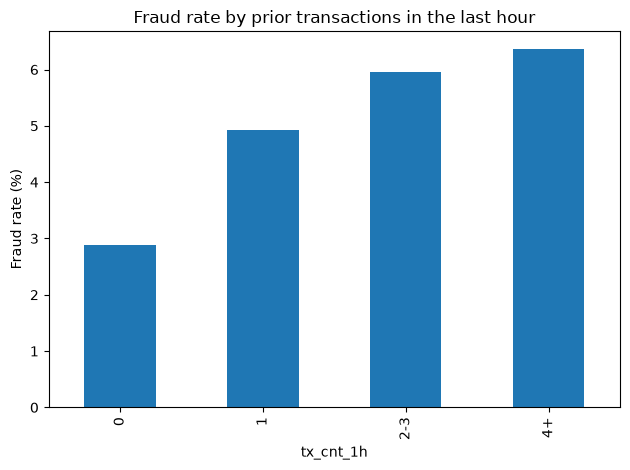

In [6]:
velocity.plot(kind="bar", y="fraud_pct", legend=False)
plt.ylabel("Fraud rate (%)")
plt.title("Fraud rate by prior transactions in the last hour")
plt.tight_layout()
plt.show()

## Rule evaluation

Baseline fraud rate is 3.5%. Rules were tested on the first 70% of time (early) and the last 30% (late).

- R1 (device profile used by 4-50 accounts, with identity record): 14.3% precision in the late period, about 4x baseline.
- R2 (identity record present, no DeviceInfo): 12.5% precision in the late period, about 3.6x baseline.
- R3 (velocity) and R4 (amount ratio) did not hold up over time and were dropped as rules.
- Stacking all rules with OR flagged about 31% of good users, so a tiered design was used instead.

In [7]:
baseline = df["isFraud"].mean() * 100

rules = {
    "device_profile_11_50": (df["has_identity"] == 1) & df["users_on_device"].between(11, 50),
    "device_profile_4_10": df["users_on_device"].between(4, 10),
    "identity_no_device_info": (df["has_identity"] == 1) & df["users_on_device"].isna(),
    "velocity_1h_ge_2": df["tx_cnt_1h"] >= 2,
    "amount_ratio_gt_1_42": df["amt_ratio"] > 1.42,
}


def evaluate(mask, subset):
    m = mask[subset]
    y = df.loc[subset, "isFraud"]
    flagged = int(m.sum())
    caught = int((m & (y == 1)).sum())
    frauds = int(y.sum())
    negatives = len(y) - frauds
    precision = caught / flagged * 100 if flagged else 0
    return {
        "flagged": flagged,
        "caught": caught,
        "precision_pct": round(precision, 2),
        "recall_pct": round(caught / frauds * 100, 2),
        "fpr_pct": round((flagged - caught) / negatives * 100, 2),
        "lift": round(precision / (y.mean() * 100), 2),
    }


full = pd.Series(True, index=df.index)
late = df["TransactionDT"] > df["TransactionDT"].quantile(0.7)

combined = pd.concat(list(rules.values()), axis=1).any(axis=1)
all_rules = {**rules, "any_rule": combined}

table_full = pd.DataFrame({k: evaluate(v, full) for k, v in all_rules.items()}).T
table_late = pd.DataFrame({k: evaluate(v, late) for k, v in all_rules.items()}).T

pd.concat({"all_data": table_full, "last_30pct_of_time": table_late}, axis=1)

all_data                                            \
                          flagged   caught precision_pct recall_pct fpr_pct   
device_profile_11_50      15488.0   2410.0         15.56      11.66    2.29   
device_profile_4_10        4367.0    536.0         12.27       2.59    0.67   
identity_no_device_info   25567.0   2711.0         10.60      13.12    4.01   
velocity_1h_ge_2          60199.0   3652.0          6.07      17.67    9.92   
amount_ratio_gt_1_42     109920.0   5233.0          4.76      25.33   18.37   
any_rule                 187692.0  11460.0          6.11      55.46   30.92   

                              last_30pct_of_time                        \
                         lift            flagged  caught precision_pct   
device_profile_11_50     4.45             4779.0   705.0         14.75   
device_profile_4_10      3.51             1328.0   169.0         12.73   
identity_no_device_info  3.03             7018.0   875.0         12.47   
velocity_1h_ge_2         1.73            17152.0   934.0          5.45   
amount_ratio_gt_1_42     1.36            31057.0  1664.0          5.36   
any_rule                 1.74            53896.0  3460.0          6.42   

                                                  
                        recall_pct fpr_pct  lift  
device_profile_11_50         11.51    2.38  4.27  
device_profile_4_10           2.76    0.68  3.68  
identity_no_device_info      14.29    3.59  3.61  
velocity_1h_ge_2             15.25    9.48  1.58  
amount_ratio_gt_1_42         27.17   17.19  1.55  
any_rule                     56.49   29.49  1.86

In [8]:
early = ~late

sweep = {}
for t in [2, 3, 4, 6, 10]:
    sweep[f"velocity_1h_ge_{t}"] = df["tx_cnt_1h"] >= t
for t in [1.42, 2, 3, 5, 10]:
    sweep[f"amount_ratio_gt_{t}"] = df["amt_ratio"] > t

pd.DataFrame({k: evaluate(v, early) for k, v in sweep.items()}).T

,flagged,caught,precision_pct,recall_pct,fpr_pct,lift
velocity_1h_ge_2,43047.0,2718.0,6.31,18.70,10.11,1.80
velocity_1h_ge_3,21846.0,1473.0,6.74,10.13,5.11,1.92
velocity_1h_ge_4,12183.0,866.0,7.11,5.96,2.84,2.02
velocity_1h_ge_6,4630.0,344.0,7.43,2.37,1.07,2.11
velocity_1h_ge_10,1123.0,111.0,9.88,0.76,0.25,2.81
amount_ratio_gt_1.42,78863.0,3569.0,4.53,24.55,18.88,1.29
amount_ratio_gt_2,45896.0,2069.0,4.51,14.23,10.99,1.28
amount_ratio_gt_3,23116.0,946.0,4.09,6.51,5.56,1.16
amount_ratio_gt_5,9300.0,331.0,3.56,2.28,2.25,1.01
amount_ratio_gt_10,2635.0,55.0,2.09,0.38,0.65,0.59


In [9]:
V_T = 4
A_T = 3

final = {
    "R1_device_profile_4_50": (df["has_identity"] == 1) & df["users_on_device"].between(4, 50),
    "R2_identity_no_device_info": (df["has_identity"] == 1) & df["users_on_device"].isna(),
    "R3_velocity": df["tx_cnt_1h"] >= V_T,
    "R4_amount_ratio": df["amt_ratio"] > A_T,
}

fired = pd.concat(list(final.values()), axis=1).sum(axis=1)
tier = final["R1_device_profile_4_50"] | final["R2_identity_no_device_info"]

candidates = {
    **final,
    "high_precision_tier_R1_or_R2": tier,
    "two_or_more_rules": fired >= 2,
    "tier_or_two_or_more": tier | (fired >= 2),
}

res_early = pd.DataFrame({k: evaluate(v, early) for k, v in candidates.items()}).T
res_late = pd.DataFrame({k: evaluate(v, late) for k, v in candidates.items()}).T
pd.concat({"early_70pct": res_early, "late_30pct": res_late}, axis=1)

early_70pct                                   \
                                 flagged  caught precision_pct recall_pct   
R1_device_profile_4_50           13748.0  2072.0         15.07      14.25   
R2_identity_no_device_info       18549.0  1836.0          9.90      12.63   
R3_velocity                      12183.0   866.0          7.11       5.96   
R4_amount_ratio                  23116.0   946.0          4.09       6.51   
high_precision_tier_R1_or_R2     32297.0  3908.0         12.10      26.88   
two_or_more_rules                 5084.0   565.0         11.11       3.89   
tier_or_two_or_more              32743.0  3931.0         12.01      27.04   

                                           late_30pct                        \
                             fpr_pct  lift    flagged  caught precision_pct   
R1_device_profile_4_50          2.93  4.29     6107.0   874.0         14.31   
R2_identity_no_device_info      4.19  2.81     7018.0   875.0         12.47   
R3_velocity                     2.84  2.02     4743.0   211.0          4.45   
R4_amount_ratio                 5.56  1.16     8899.0   486.0          5.46   
high_precision_tier_R1_or_R2    7.12  3.44    13125.0  1749.0         13.33   
two_or_more_rules               1.13  3.16     1592.0   155.0          9.74   
tier_or_two_or_more             7.22  3.41    13240.0  1755.0         13.26   

                                                       
                             recall_pct fpr_pct  lift  
R1_device_profile_4_50            14.27    3.06  4.14  
R2_identity_no_device_info        14.29    3.59  3.61  
R3_velocity                        3.44    2.65  1.29  
R4_amount_ratio                    7.93    4.92  1.58  
high_precision_tier_R1_or_R2      28.56    6.65  3.85  
two_or_more_rules                  2.53    0.84  2.82  
tier_or_two_or_more               28.65    6.71  3.83

## Rules vs Isolation Forest

The forest ranks transactions better overall (AUC 0.71) but the rule tier is more precise at the same alert volume (13.3% vs 8.3%).
Only 383 frauds are caught by both, so the methods catch different fraud and suit a two-queue design: tier first, forest-only hits as lower-priority review.

In [14]:
import numpy as np
from sklearn.ensemble import IsolationForest
from sklearn.metrics import roc_auc_score

feat_cols = [
    "tx_cnt_1h", "tx_cnt_24h", "tx_cnt_7d", "amt_ratio",
    "secs_since_prev", "TransactionAmt", "has_identity", "users_on_device",
]

X = df[feat_cols].copy()
X["TransactionAmt"] = np.log1p(X["TransactionAmt"])
X["amt_ratio"] = np.log1p(X["amt_ratio"].fillna(1))
X["secs_since_prev"] = np.log1p(X["secs_since_prev"].fillna(X["secs_since_prev"].max()))
X["users_on_device"] = np.log1p(X["users_on_device"].fillna(0))
X["tx_cnt_1h"] = np.log1p(X["tx_cnt_1h"])
X["tx_cnt_24h"] = np.log1p(X["tx_cnt_24h"])
X["tx_cnt_7d"] = np.log1p(X["tx_cnt_7d"])

model = IsolationForest(n_estimators=200, random_state=42, n_jobs=-1)
model.fit(X[early])

scores = pd.Series(-model.score_samples(X), index=df.index)

share = tier[late].mean()
threshold = np.quantile(scores[late], 1 - share)
ml = scores >= threshold

setups = {
    "rules_tier": tier,
    "isolation_forest": ml,
    "tier_and_forest": tier & ml,
    "tier_or_forest": tier | ml,
}

print("forest AUC on late period:", round(roc_auc_score(df.loc[late, "isFraud"], scores[late]), 3))
pd.DataFrame({k: evaluate(v, late) for k, v in setups.items()}).T

forest AUC on late period: 0.709


,flagged,caught,precision_pct,recall_pct,fpr_pct,lift
rules_tier,13125.0,1749.0,13.33,28.56,6.65,3.85
isolation_forest,13125.0,1090.0,8.30,17.80,7.04,2.40
tier_and_forest,3622.0,383.0,10.57,6.25,1.89,3.06
tier_or_forest,22628.0,2456.0,10.85,40.10,11.79,3.14


Simulated rollout (treatment vs holdout)

Method: pseudo-users in the late period were randomly assigned to treatment (policy applied) or holdout.
The policy is assumed to stop every transaction it flags, so the reduction reflects the rule's recall, not proven real-world impact.

Result: the tier policy cut the fraud rate from [X]% to [Y]%, a [Z]% reduction (95% cluster-bootstrap interval [low] to [high]), at a false-decline rate of about 5.9%.

Limitations:
- Simulation only. Real fraudsters adapt, and a 5.9% false-decline rate is too high for hard blocks, so the tier would drive step-up verification.
- The z-test treats transactions as independent, so the cluster bootstrap is the more reliable interval.
- Device counts use the whole dataset, so device-based results are slightly optimistic.

In [15]:
from scipy.stats import norm

rng = np.random.default_rng(42)
users = df.loc[late, "user_key"].unique()
assign = pd.Series(rng.random(len(users)) < 0.5, index=users)
treated = df["user_key"].map(assign).fillna(False).astype(bool)


def run_experiment(policy):
    fraud = df["isFraud"] == 1
    t = late & treated
    h = late & ~treated
    n_t, n_h = int(t.sum()), int(h.sum())
    x_t = int((fraud & ~policy)[t].sum())
    x_h = int(fraud[h].sum())
    p_t, p_h = x_t / n_t, x_h / n_h
    pooled = (x_t + x_h) / (n_t + n_h)
    z = (p_t - p_h) / np.sqrt(pooled * (1 - pooled) * (1 / n_t + 1 / n_h))
    se = np.sqrt(p_t * (1 - p_t) / n_t + p_h * (1 - p_h) / n_h)
    diff = p_t - p_h
    legit_t = int((~fraud)[t].sum())
    false_declines = int((policy & ~fraud)[t].sum())
    amt_t = df.loc[t & fraud & ~policy, "TransactionAmt"].sum() / n_t * 1000
    amt_h = df.loc[h & fraud, "TransactionAmt"].sum() / n_h * 1000
    return {
        "n_treatment": n_t,
        "n_holdout": n_h,
        "fraud_through_treatment_pct": round(p_t * 100, 3),
        "fraud_holdout_pct": round(p_h * 100, 3),
        "relative_reduction_pct": round((1 - p_t / p_h) * 100, 1),
        "diff_ci95_low_pp": round((diff - 1.96 * se) * 100, 3),
        "diff_ci95_high_pp": round((diff + 1.96 * se) * 100, 3),
        "p_value": float(f"{2 * (1 - norm.cdf(abs(z))):.2e}"),
        "false_decline_pct": round(false_declines / legit_t * 100, 2),
        "fraud_loss_per_1k_tx_treatment": round(amt_t, 0),
        "fraud_loss_per_1k_tx_holdout": round(amt_h, 0),
    }


pd.DataFrame({
    "tier_R1_or_R2": run_experiment(tier),
    "tier_or_forest": run_experiment(tier | ml),
}).T

,n_treatment,n_holdout,fraud_through_treatment_pct,fraud_holdout_pct,relative_reduction_pct,diff_ci95_low_pp,diff_ci95_high_pp,p_value,false_decline_pct,fraud_loss_per_1k_tx_treatment,fraud_loss_per_1k_tx_holdout
tier_R1_or_R2,87757.0,89405.0,2.447,3.566,31.4,-1.278,-0.960,0.0,5.93,4766.0,5613.0
tier_or_forest,87757.0,89405.0,2.059,3.566,42.3,-1.660,-1.353,0.0,10.21,3504.0,5613.0


In [ ]:
out = df[[
    "TransactionID", "user_key", "TransactionDT", "TransactionAmt", "isFraud",
    "tx_cnt_1h", "amt_ratio", "has_identity", "users_on_device",
]].copy()
out["r1_device_profile"] = final["R1_device_profile_4_50"].astype(int)
out["r2_identity_no_device"] = final["R2_identity_no_device_info"].astype(int)
out["tier_flag"] = tier.astype(int)
out["forest_score"] = scores.round(5)
out["forest_flag"] = ml.astype(int)
out["period"] = np.where(late, "late", "early")
out["arm"] = np.where(late, np.where(treated, "treatment", "holdout"), "none")

out.to_sql("tx_scored", engine, if_exists="replace", index=False, chunksize=20000, method="multi")

In [ ]:
t = late & treated
h = late & ~treated
print("raw fraud pct, treatment arm:", round(df.loc[t, "isFraud"].mean() * 100, 3))
print("raw fraud pct, holdout arm:  ", round(df.loc[h, "isFraud"].mean() * 100, 3))


def cluster_bootstrap(policy, reps=500, seed=1):
    g = pd.DataFrame({
        "user": df.loc[late, "user_key"],
        "treated": treated[late],
        "n": 1,
        "fraud": df.loc[late, "isFraud"],
        "through": (df["isFraud"] == 1)[late] & ~policy[late],
    }).groupby("user").agg(
        treated=("treated", "first"),
        n=("n", "sum"),
        fraud=("fraud", "sum"),
        through=("through", "sum"),
    )
    gt = g[g["treated"]]
    gh = g[~g["treated"]]
    rng = np.random.default_rng(seed)
    out = []
    for _ in range(reps):
        st = gt.iloc[rng.integers(0, len(gt), len(gt))]
        sh = gh.iloc[rng.integers(0, len(gh), len(gh))]
        out.append(1 - (st["through"].sum() / st["n"].sum()) / (sh["fraud"].sum() / sh["n"].sum()))
    return np.percentile(out, [2.5, 50, 97.5]) * 100


for name, policy in [("tier", tier), ("tier_or_forest", tier | ml)]:
    print(name, "reduction pct [2.5, 50, 97.5]:", cluster_bootstrap(policy).round(1))

raw fraud pct, treatment arm: 3.347
raw fraud pct, holdout arm:   3.566
tier reduction pct [2.5, 50, 97.5]: [13.6 31.1 44. ]
tier_or_forest reduction pct [2.5, 50, 97.5]: [27.4 42.1 52.4]
